# Modelado · Regresión de los días de mala salud física
### Proyecto de Aprendizaje Automático · Encuesta de salud del consorcio de atención primaria

**Objetivo.** Estimar `dias_salud_fisica_mala` (entero de 0 a 30) a partir del resto de la encuesta, como indicador de carga de enfermedad para planificar la demanda asistencial.

Se sigue el mismo protocolo que en `03_modelado_clasificacion.ipynb`: partición 80/20 estratificada, toda la selección con validación cruzada dentro de train y **una única evaluación en test** al final. Las funciones están en `src/modelado.py`, de modo que el modelo que se valida aquí es exactamente el que sirve la API.

> 🔧 **CLAUDE — REVISAR Y BORRAR ESTA CELDA**
>
> - Notebook nuevo. Usa funciones nuevas de `src/modelado.py`: `RegresorAcotado`, `DosPartes`, `boosting_regresion`, `dos_partes`, `construir_regresion`, `candidatos_regresion`, `validacion_cruzada_regresion`, `metricas_regresion`, `evaluar_cv_regresion`, `metricas_regresion_con_ic` y la entrada `"regresion"` de `CONFIG_FINAL`.
> - Decisión abierta (sección 5): modelo de la mediana (mejor MAE) frente al de la media (mejor RMSE y R²). Conviene confirmar con Borja qué métrica usará en la fase competitiva.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import ParameterSampler

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import eda_utils as eu
import modelado as md
import preprocesamiento as pp

warnings.filterwarnings("ignore", message=".*valores no reconocidos.*")
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
eu.configurar_estilo()
LINEA = "regresion"

## 1. Datos y protocolo de evaluación

- **Partición 80/20** con la semilla del proyecto, estratificada por tramos del objetivo (**0 / 1-29 / 30 días**, `pp.tramos_regresion`), para que train y test conserven la forma cero-inflada y bimodal.
- **Entrada**: solo las columnas crudas que necesita la línea (`pp.columnas_crudas`). Ni datos personales, ni identificadores, ni `diabetes`: en el PC1 se comprobó que el objetivo cruzado no aporta (decisión #13) y la API no debe exigirlo.
- **Validación cruzada** de 5 pliegues estratificados por los mismos tramos y fijos para todos los modelos, así las comparaciones son pareadas.
- Todas las predicciones se **recortan a [0, 30]** (`md.RegresorAcotado`): fuera de ese rango no tienen sentido.

In [2]:
crudo = pp.cargar_datos()
X_train_todo, X_test_todo, y_train, y_test = pp.dividir(crudo, LINEA)
COLUMNAS = pp.columnas_crudas(LINEA)
X_train, X_test = X_train_todo[COLUMNAS], X_test_todo[COLUMNAS]
PLIEGUES = md.validacion_cruzada_regresion(y_train)


def reparto(y):
    tramos = pp.tramos_regresion(y).value_counts(normalize=True).reindex(["0", "1-29", "30"])
    return pd.Series({"pacientes": len(y), "media": y.mean(), "mediana": y.median(),
                      **{f"% {t} días": v for t, v in tramos.items()}})


pd.DataFrame({"train": reparto(y_train), "test": reparto(y_test)}).T.style.format(
    {"pacientes": "{:,.0f}", "media": "{:.2f}", "mediana": "{:.0f}",
     "% 0 días": "{:.1%}", "% 1-29 días": "{:.1%}", "% 30 días": "{:.1%}"})

,pacientes,media,mediana,% 0 días,% 1-29 días,% 30 días
train,"10,200",4.98,0,60.3%,30.3%,9.3%
test,"2,550",5.00,0,60.3%,30.4%,9.3%


In [3]:
print("Columnas que pide el modelo:", COLUMNAS)
assert not set(COLUMNAS) & set(pp.COLS_PII + pp.COLS_GESTION + [pp.COL_ID, pp.TARGET_CLASIF, pp.TARGET_REGR])

Columnas que pide el modelo: ['imc', 'dias_salud_mental_mala', 'grupo_edad', 'salud_general', 'nivel_educativo', 'nivel_ingresos', 'presion_alta', 'colesterol_alto', 'chequeo_colesterol_5a', 'fumador', 'ictus', 'enfermedad_cardiaca', 'actividad_fisica', 'consume_fruta', 'consume_verdura', 'consumo_alcohol_alto', 'dificultad_caminar', 'sexo']


## 2. Métrica: qué se optimiza y por qué

El EDA (sección 5.2) mostró que el objetivo tiene un **60 % de ceros**, un **9 % en 30** y redondeos a múltiplos de 5. Con esta forma, la métrica decide qué modelo gana:

| Métrica | Qué premia | Predicción óptima |
|---|---|---|
| **MAE** | Acertar el valor típico; no la dominan los pacientes con 30 días | La **mediana** condicional |
| **RMSE** | No fallar mucho en los casos extremos | La **media** condicional |

La métrica principal es el **MAE** (decisión #12 del EDA): se mide en días y es robusta a los extremos. Pero no se mira sola:

- **RMSE y R²**, para ver qué se pierde en los casos graves.
- **MAE por tramos** (0, 1-29 y 30 días), porque un modelo puede tener buen MAE solo por acertar los ceros.
- **Media predicha** frente a la real: para planificar la demanda se suman los días de todos los pacientes, y ese total lo da la media, no la mediana.

## 3. Primera ronda: comparación de familias

Nueve candidatos con hiperparámetros razonables, evaluados con los mismos 5 pliegues:

| Familia | Candidatos | Qué predice |
|---|---|---|
| Referencias | Dummy media; Dummy mediana (0 días a todos) | Una constante |
| Lineales | Ridge; GLM de Poisson (recuento con enlace logarítmico) | La media |
| Boosting | Pérdida cuadrática; Poisson; absoluta | Media; media de un recuento; mediana |
| Dos partes (*hurdle*) | Un clasificador estima P(días > 0) y un regresor los días cuando hay alguno | «Media»: P × días. «Mediana»: 0 si P < 0,5 y, si no, la mediana de los días |

Los lineales usan las variables originales sin las derivadas (decisión #9).

In [4]:
resultados = {}
for nombre, estimador in md.candidatos_regresion().items():
    resultados[nombre] = md.evaluar_cv_regresion(md.construir_regresion(estimador), X_train, y_train, PLIEGUES)

COLS_TABLA = ["MAE", "± MAE", "RMSE", "R²", "MAE (0 días)", "MAE (1-29 días)", "MAE (30 días)", "Media predicha",
              "Tiempo ajuste (s)"]
ronda1 = pd.DataFrame({n: r.mean() for n, r in resultados.items()}).T.sort_values("MAE")
ronda1["± MAE"] = [resultados[n]["MAE"].std() for n in ronda1.index]
print(f"Media real de train: {y_train.mean():.2f} días")
ronda1[COLS_TABLA].style.format("{:.3f}").highlight_min(subset=["MAE", "RMSE"], color="#d8ecd8")

Media real de train: 4.98 días


,MAE,± MAE,RMSE,R²,MAE (0 días),MAE (1-29 días),MAE (30 días),Media predicha,Tiempo ajuste (s)
Dos partes (mediana),3.688,0.101,7.488,0.368,1.291,6.017,11.608,4.385,1.931
Boosting (Poisson),4.264,0.100,7.057,0.439,2.462,4.766,14.267,4.935,1.454
Boosting (error cuadrático),4.269,0.087,7.034,0.442,2.485,4.797,14.077,4.971,1.139
Dos partes (media),4.271,0.082,7.009,0.447,2.500,4.735,14.199,4.967,1.764
GLM Poisson,4.360,0.100,7.116,0.429,2.648,4.510,14.931,4.843,0.474
Ridge,4.782,0.076,7.283,0.402,3.065,4.702,16.135,5.256,0.186
Boosting (error absoluto),4.976,0.109,10.655,-0.279,0.000,7.166,30.000,0.000,0.487
Dummy (mediana = 0),4.976,0.109,10.655,-0.279,0.000,7.166,30.000,0.000,0.185
Dummy (media),6.847,0.063,9.422,-0.000,4.976,4.969,25.024,4.976,0.172


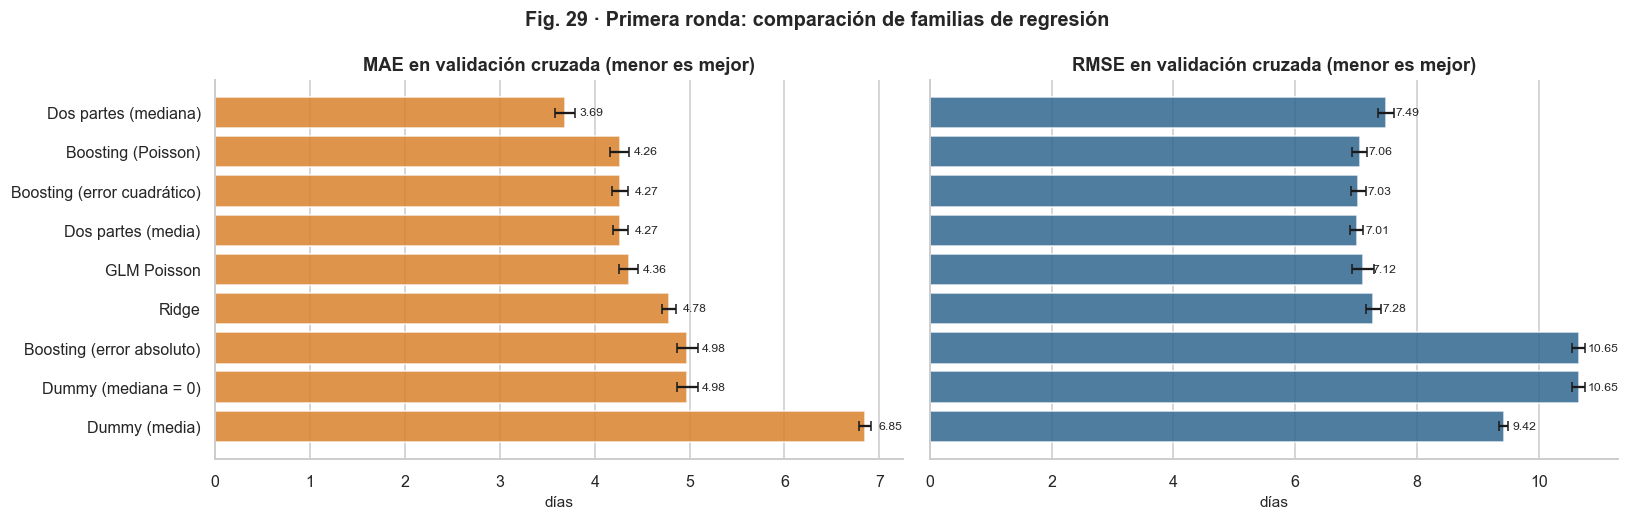

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
orden = ronda1.index[::-1]
for ax, metrica, color in zip(axes, ["MAE", "RMSE"], [eu.NARANJA, eu.AZUL]):
    valores = ronda1.loc[orden, metrica]
    ax.barh(orden, valores, xerr=[resultados[n][metrica].std() for n in orden], color=color, alpha=0.85, capsize=3)
    for i, v in enumerate(valores):
        ax.text(v + 0.15, i, f"{v:.2f}", va="center", fontsize=8)
    ax.set(title=f"{metrica} en validación cruzada (menor es mejor)", xlabel="días")
    eu.rejilla_x(ax)
fig.suptitle("Fig. 29 · Primera ronda: comparación de familias de regresión")
fig.tight_layout()
eu.guardar_figura(fig, "fig29_comparativa_regresion")
plt.show()

**Hallazgos**

- **Dos estrategias claras.** Los modelos que predicen la media (boosting cuadrático, boosting de Poisson y dos partes con media) empatan en MAE (≈ 4,27) y son los mejores en RMSE (≈ 7,0) y R² (≈ 0,44). El modelo de **dos partes con mediana** baja el MAE a **3,69**, un 13 % menos, a cambio de peor RMSE (7,49) y R² (0,37).
- **El boosting con error absoluto no aprende**: predice 0 a todo el mundo, igual que la Dummy de la mediana. Con un 60 % de ceros, el gradiente del error absoluto empuja todo hacia 0 desde la primera iteración. Para predecir la mediana hace falta separar el problema en dos partes.
- **Los lineales quedan por detrás** (GLM de Poisson 4,36; Ridge 4,78): hay relaciones no lineales e interacciones que el boosting sí capta.
- **Todos superan con claridad a las referencias**: la Dummy de la media tiene un MAE de 6,85 y la de la mediana, un RMSE de 10,65.
- El MAE por tramos explica la diferencia: el modelo de mediana acierta mucho mejor los ceros (1,29 frente a 2,46 días) y los 30 días (11,6 frente a 14,3), pero falla más en los intermedios (6,0 frente a 4,8).
- **Media predicha**: los modelos de la media aciertan el total (4,94 a 4,97 días frente a 4,98 reales); el de mediana lo subestima (4,39).

## 4. Ajuste de las dos mejores familias

Se ajusta lo mejor de cada enfoque:

1. **Boosting de Poisson** (el mejor de los que predicen la media): búsqueda aleatoria de 25 combinaciones con los mismos pliegues, eligiendo por RMSE, que es la métrica coherente con predecir la media.
2. **Dos partes con mediana** (el mejor en MAE): su hiperparámetro clave es el umbral de P(días > 0) a partir del cual se predicen días.

In [6]:
espacio = {
    "learning_rate": loguniform(0.01, 0.2),
    "max_iter": randint(100, 800),
    "max_leaf_nodes": randint(4, 32),
    "min_samples_leaf": randint(20, 200),
    "l2_regularization": loguniform(1e-3, 10),
}
filas = []
for params in ParameterSampler(espacio, n_iter=25, random_state=pp.SEMILLA):
    params = {k: round(float(v), 4) if isinstance(v, float) else int(v) for k, v in params.items()}
    modelo = md.construir_regresion(md.boosting_regresion("poisson", **params))
    filas.append(params | md.evaluar_cv_regresion(modelo, X_train, y_train, PLIEGUES)[["MAE", "RMSE", "R²"]].mean().to_dict())
busqueda = pd.DataFrame(filas).sort_values("RMSE")
MEJOR_POISSON = {k: (int(v) if k in ("max_iter", "max_leaf_nodes", "min_samples_leaf") else float(v))
                 for k, v in busqueda.iloc[0][list(espacio)].items()}
print("Mejor boosting de Poisson:", MEJOR_POISSON)
busqueda.head(8).style.format({"learning_rate": "{:.4f}", "l2_regularization": "{:.4f}",
                               "MAE": "{:.3f}", "RMSE": "{:.3f}", "R²": "{:.3f}"})

Mejor boosting de Poisson: {'learning_rate': 0.0143, 'max_iter': 561, 'max_leaf_nodes': 6, 'min_samples_leaf': 20, 'l2_regularization': 0.0774}


,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAE,RMSE,R²
22,0.0774,0.0143,561,6,20,4.276,6.949,0.456
12,0.0177,0.0475,205,7,73,4.254,6.955,0.455
1,0.0042,0.0160,430,14,107,4.257,6.966,0.453
23,0.7708,0.0203,497,10,46,4.251,6.967,0.453
2,0.0216,0.0153,230,25,72,4.340,6.983,0.450
18,0.0062,0.0102,238,22,100,4.456,7.001,0.448
8,0.0048,0.0122,487,28,79,4.275,7.012,0.446
17,1.6173,0.0125,620,27,148,4.267,7.029,0.443


In [7]:
filas = []
for umbral in [0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7]:
    modelo = md.construir_regresion(md.dos_partes(umbral=umbral))
    r = md.evaluar_cv_regresion(modelo, X_train, y_train, PLIEGUES)
    filas.append({"umbral": umbral} | r[["MAE", "RMSE", "R²", "MAE (0 días)", "MAE (30 días)", "Media predicha"]].mean().to_dict())
umbrales = pd.DataFrame(filas).set_index("umbral")
umbrales.style.format("{:.3f}")

,MAE,RMSE,R²,MAE (0 días),MAE (30 días),Media predicha
umbral,,,,,,
0.300000,4.091,7.353,0.391,2.277,10.816,5.402
0.400000,3.869,7.381,0.386,1.778,11.047,4.934
0.450000,3.794,7.442,0.376,1.561,11.304,4.689
0.500000,3.688,7.488,0.368,1.291,11.608,4.385
0.550000,3.595,7.543,0.359,1.058,11.906,4.089
0.600000,3.555,7.633,0.343,0.902,12.281,3.850
0.700000,3.534,7.843,0.307,0.632,13.155,3.401


**Hallazgos**

- **Boosting de Poisson**: la búsqueda mejora poco (RMSE de 7,06 a 6,95; R² de 0,44 a 0,46). Combinaciones muy distintas quedan a menos de 0,02 días entre sí: con estas variables el modelo está cerca de su techo. Se elige la de menor RMSE.
- **Umbral del modelo de dos partes**: el MAE sigue bajando al subir el umbral (3,69 con 0,5; 3,53 con 0,7), pero solo porque predice 0 a más pacientes. La media predicha cae de 4,39 a 3,40 días (frente a 4,98 reales) y el R² baja de 0,37 a 0,31. Es la trampa del MAE con un 60 % de ceros: premia predecir 0.
- Por eso **el umbral se fija en 0,5 y no se ajusta**. Es el valor que corresponde a la mediana por definición: si la probabilidad de tener algún día es menor que 0,5, la mediana de los días es 0. No es un número elegido para mejorar la métrica.

## 5. Elección final: ¿mediana o media?

Los dos finalistas se comparan con **validación cruzada repetida 5 × 5** (25 particiones distintas) para saber si la diferencia es estable y no fruto de una partición concreta.

In [8]:
UMBRAL = 0.5
pliegues_rep = md.validacion_cruzada_regresion(y_train, repeticiones=5)
finalistas = {
    "Dos partes (mediana)": md.dos_partes(umbral=UMBRAL),
    "Boosting Poisson ajustado": md.boosting_regresion("poisson", **MEJOR_POISSON),
}
rep = {n: md.evaluar_cv_regresion(md.construir_regresion(e), X_train, y_train, pliegues_rep) for n, e in finalistas.items()}
tabla_rep = pd.DataFrame({n: r.mean() for n, r in rep.items()}).T
tabla_rep["± MAE"] = [rep[n]["MAE"].std() for n in tabla_rep.index]
dif = rep["Dos partes (mediana)"]["MAE"] - rep["Boosting Poisson ajustado"]["MAE"]
print(f"MAE pareado (dos partes − Poisson): {dif.mean():+.3f} días; dos partes gana en {(dif < 0).mean():.0%} de las 25 particiones")
tabla_rep[COLS_TABLA].style.format("{:.3f}")

MAE pareado (dos partes − Poisson): -0.578 días; dos partes gana en 100% de las 25 particiones


,MAE,± MAE,RMSE,R²,MAE (0 días),MAE (1-29 días),MAE (30 días),Media predicha,Tiempo ajuste (s)
Dos partes (mediana),3.697,0.101,7.480,0.369,1.318,5.988,11.623,4.389,0.631
Boosting Poisson ajustado,4.275,0.068,6.955,0.455,2.549,4.587,14.408,4.963,0.572


**Resultado.** En las 25 particiones, el modelo de dos partes tiene **0,58 días menos de MAE** que el boosting de Poisson ajustado y gana en todas. El de Poisson gana en RMSE (6,96 frente a 7,48) y en R² (0,46 frente a 0,37).

**Decisión: modelo de dos partes con mediana (umbral 0,5).**

| Criterio | Dos partes (mediana) | Boosting de Poisson |
|---|---|---|
| MAE (métrica principal, decisión #12) | **3,70** | 4,28 |
| RMSE / R² | 7,48 / 0,37 | **6,96 / 0,46** |
| Media predicha (real: 4,98) | 4,39 (−12 %) | **4,96** |
| Cómo se explica | Dos preguntas: ¿tendrá algún día de mala salud? y, si es así, ¿cuántos? | Un único modelo |

Motivos: es claramente mejor en la métrica principal, la ventaja es estable en todas las particiones y es fácil de explicar a un profesional sanitario.

**Limitación.** Al predecir la mediana, la suma de las predicciones subestima el total de días en torno a un 12 %. Si el consorcio quisiera estimar la carga total de una población, sería mejor el modelo de la media. **Pendiente de confirmar con el profesor** qué métrica usa la fase competitiva: si fuera el RMSE, el cambio es una línea en `CONFIG_FINAL` (`"estimador": "boosting_poisson"`, con los parámetros guardados en `reports/metricas_regresion.json`).

In [9]:
ELECCION = "Dos partes (mediana)"
print("CONFIG_FINAL['regresion'] =", md.CONFIG_FINAL[LINEA])
assert md.CONFIG_FINAL[LINEA]["estimador"] == "dos_partes" and md.CONFIG_FINAL[LINEA]["umbral"] == UMBRAL

CONFIG_FINAL['regresion'] = {'estimador': 'dos_partes', 'umbral': 0.5, 'params_clasificador': {}, 'params_regresor': {}}


## 6. Evaluación final en test (una sola vez)

El modelo elegido se reajusta con todo train y se evalúa **una única vez** en test (2 550 pacientes que no se han usado para nada). Los intervalos de confianza son de *bootstrap* percentil sobre los pacientes de test.

In [10]:
modelo_final = md.construir_final(LINEA).fit(X_train, y_train)
pred_test = modelo_final.predict(X_test)
pred_mediana = md.construir_regresion(DummyRegressor(strategy="median")).fit(X_train, y_train).predict(X_test)
pred_media = md.construir_regresion(DummyRegressor(strategy="mean")).fit(X_train, y_train).predict(X_test)

ic_test = md.metricas_regresion_con_ic(y_test, pred_test)
evaluacion = ic_test.assign(**{
    "CV 5×5 (train)": rep[ELECCION].mean(),
    "Dummy mediana (test)": pd.Series(md.metricas_regresion(y_test, pred_mediana)),
    "Dummy media (test)": pd.Series(md.metricas_regresion(y_test, pred_media)),
})
print(f"Media real en test: {y_test.mean():.2f} días")
evaluacion.style.format("{:.3f}")

Media real en test: 5.00 días


,valor,IC inf.,IC sup.,CV 5×5 (train),Dummy mediana (test),Dummy media (test)
MAE,3.716,3.438,3.972,3.697,4.996,6.863
RMSE,7.644,7.204,8.068,7.480,10.691,9.452
R²,0.346,0.278,0.413,0.369,-0.279,-0.000
MAE (0 días),1.268,1.057,1.500,1.318,0.000,4.976
MAE (1-29 días),5.966,5.546,6.383,5.988,7.234,5.028
MAE (30 días),12.223,10.730,13.717,11.623,30.000,25.024
Media predicha,4.428,4.098,4.740,4.389,0.000,4.976


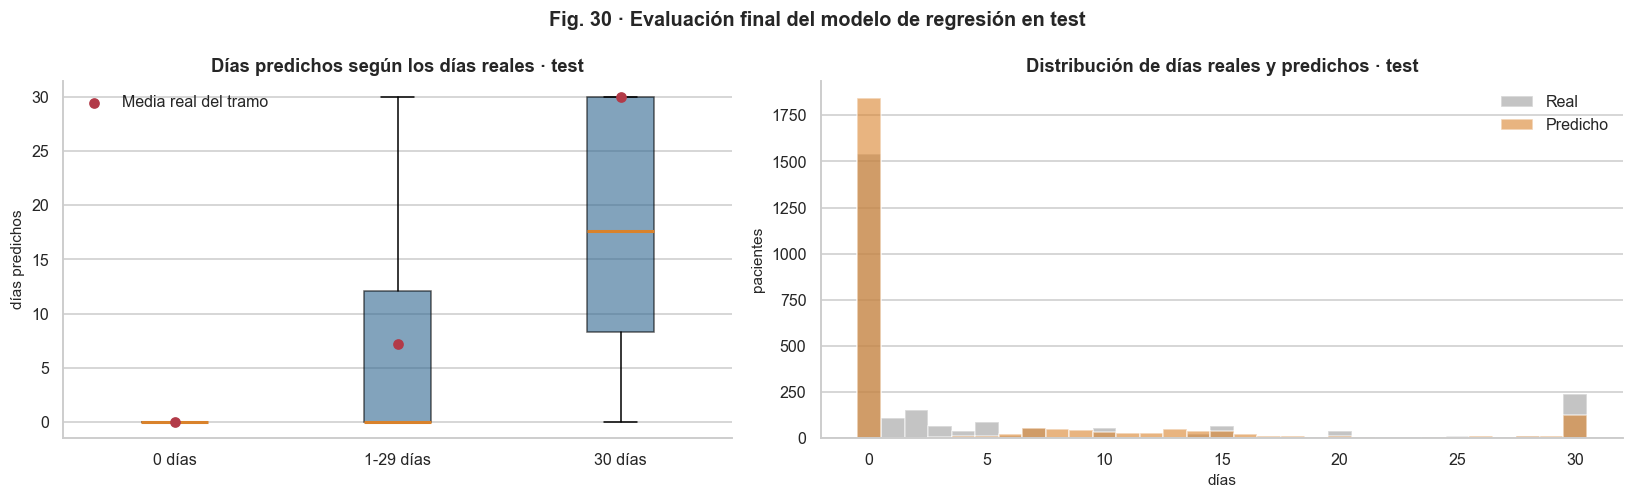

In [11]:
tramos_test = pp.tramos_regresion(y_test)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
etiquetas = ["0", "1-29", "30"]
ax.boxplot([pred_test[tramos_test == t] for t in etiquetas], tick_labels=[f"{t} días" for t in etiquetas],
           showfliers=False, patch_artist=True, boxprops=dict(facecolor=eu.AZUL, alpha=0.6),
           medianprops=dict(color=eu.NARANJA, lw=2))
ax.scatter(range(1, 4), [y_test[tramos_test == t].mean() for t in etiquetas], color=eu.ROJO, zorder=3,
           label="Media real del tramo")
ax.set(title="Días predichos según los días reales · test", ylabel="días predichos")
ax.legend(loc="upper left")
ax = axes[1]
bins = np.arange(-0.5, 31.5, 1)
ax.hist(y_test, bins=bins, alpha=0.5, color=eu.GRIS, label="Real")
ax.hist(pred_test, bins=bins, alpha=0.6, color=eu.NARANJA, label="Predicho")
ax.set(title="Distribución de días reales y predichos · test", xlabel="días", ylabel="pacientes")
ax.legend()
fig.suptitle("Fig. 30 · Evaluación final del modelo de regresión en test")
fig.tight_layout()
eu.guardar_figura(fig, "fig30_evaluacion_test_regresion")
plt.show()

**Hallazgos**

- En test, **MAE de 3,72 días** [3,44 a 3,97], igual que en validación cruzada (3,70): no hay sobreajuste. Mejora un **26 %** a la mejor referencia (Dummy de la mediana, 5,00), y su RMSE (7,64) es menor que el de la Dummy de la media (9,45).
- **R² de 0,35** [0,28 a 0,41]: el modelo explica algo más de un tercio de la variación. Es razonable para un dato autodeclarado, redondeado y que depende de muchas cosas que la encuesta no recoge.
- La figura muestra cómo trabaja. A quien declara 0 días le predice 0 casi siempre (MAE 1,27). A quien declara 30 le predice una mediana de unos 18 días. En el tramo intermedio (1 a 29 días), la mediana de las predicciones es 0: a muchos de esos pacientes el modelo no les ve señal suficiente, y es su mayor fuente de error (MAE 5,97).
- La media predicha (4,43) queda por debajo de la real (5,00): es la limitación anunciada en la sección 5.

## 7. Interpretación: ¿qué variables usa el modelo?

Importancia por permutación en test: cuánto empeora el MAE si se desordena una variable y se rompe su relación con el objetivo. Se calcula sobre las columnas crudas, que es lo que recibe el modelo.

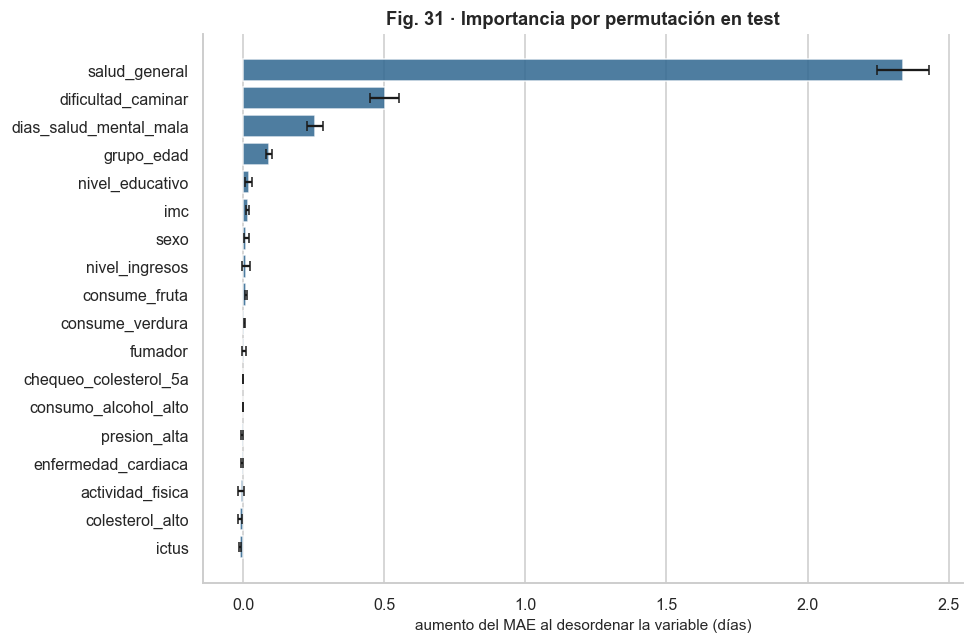

,aumento del MAE (días),±
salud_general,2.338,0.092
dificultad_caminar,0.501,0.052
dias_salud_mental_mala,0.255,0.029
grupo_edad,0.091,0.012
nivel_educativo,0.019,0.011
imc,0.015,0.006
sexo,0.011,0.009
nivel_ingresos,0.010,0.015


In [12]:
imp = permutation_importance(modelo_final, X_test, y_test, scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=pp.SEMILLA, n_jobs=-1)
importancias = pd.DataFrame({"aumento del MAE (días)": imp.importances_mean, "±": imp.importances_std},
                            index=COLUMNAS).sort_values("aumento del MAE (días)")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importancias.index, importancias["aumento del MAE (días)"], xerr=importancias["±"],
        color=eu.AZUL, alpha=0.85, capsize=3)
ax.set(title="Fig. 31 · Importancia por permutación en test", xlabel="aumento del MAE al desordenar la variable (días)")
eu.rejilla_x(ax)
fig.tight_layout()
eu.guardar_figura(fig, "fig31_importancia_regresion")
plt.show()
importancias.sort_values("aumento del MAE (días)", ascending=False).head(8).style.format("{:.3f}")

**Hallazgos**

- **La salud autopercibida domina**: desordenarla empeora el MAE en 2,3 días. Es coherente con el EDA (ρ = 0,50): quien dice que su salud es mala declara muchos días de mala salud física. No es una fuga, porque se recoge en la misma encuesta y estará disponible al predecir.
- Le siguen la **dificultad para caminar** (0,5 días), los **días de mala salud mental** (0,26) y la **edad** (0,09). El resto aporta muy poco por separado.
- Las variables clínicas (hipertensión, colesterol, cardiopatía, ictus) apenas influyen una vez se conoce la salud percibida, que ya recoge su efecto. Sus valores negativos están dentro del margen de error.
- Para el informe: el modelo es fácil de explicar, pero depende mucho de una sola pregunta. Si esa respuesta falta, se imputa con la mediana y la predicción pierde precisión.

## 8. Comprobaciones finales sobre el modelo que se va a servir

La API recibirá filas **crudas**, con codificaciones mezcladas y valores ausentes, y debe devolver exactamente una predicción por fila.

In [13]:
muestra = X_test_todo.head(20)[COLUMNAS].copy()
con_nulos = muestra.copy()
con_nulos.iloc[:5] = np.nan
sucias = muestra.copy()
sucias["presion_alta"] = ["SI", "True", "1.0", "no", "NO"] * 4

pred = modelo_final.predict(muestra)
comprobaciones = {
    "Una predicción por paciente": len(pred) == len(muestra),
    "Todas en [0, 30]": bool(((pred >= 0) & (pred <= 30)).all()),
    "Filas totalmente vacías también se predicen": len(modelo_final.predict(con_nulos)) == len(con_nulos),
    "Acepta codificaciones mezcladas": bool(np.isfinite(modelo_final.predict(sucias)).all()),
    "Pide exactamente las columnas crudas previstas": list(modelo_final.feature_names_in_) == COLUMNAS,
}
assert all(comprobaciones.values())
pd.Series(comprobaciones, name="OK").to_frame()

,OK
Una predicción por paciente,True
"Todas en [0, 30]",True
Filas totalmente vacías también se predicen,True
Acepta codificaciones mezcladas,True
Pide exactamente las columnas crudas previstas,True


In [14]:
salida = {
    "linea": LINEA,
    "modelo": ELECCION,
    "config": md.CONFIG_FINAL[LINEA],
    "columnas_entrada": COLUMNAS,
    "cv_repetida_5x5": rep[ELECCION][["MAE", "RMSE", "R²"]].mean().round(4).to_dict(),
    "alternativa_media": {
        "modelo": "Boosting Poisson ajustado",
        "params": MEJOR_POISSON,
        "cv_repetida_5x5": rep["Boosting Poisson ajustado"][["MAE", "RMSE", "R²"]].mean().round(4).to_dict(),
    },
    "test": {m: {k: round(float(v), 4) for k, v in fila.items()} for m, fila in ic_test.iterrows()},
}
ruta = pp.RUTA_PROYECTO / "reports" / "metricas_regresion.json"
ruta.write_text(json.dumps(salida, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Guardado {ruta.relative_to(pp.RUTA_PROYECTO)}")

Guardado reports\metricas_regresion.json


## 9. Siguiente paso: artefacto y API

Como en clasificación, el artefacto que sirve la API lo genera un script que reajusta `md.CONFIG_FINAL` con **todo** el conjunto de desarrollo (12 750 pacientes):

```bash
python src/entrenar.py regresion             # → artifacts/proy_modelo_regresion.joblib (+ .json)
uvicorn src.servicio:app --port 8000         # la API declara ya clasificacion y regresion
python -m pytest tests -q                    # pruebas del servicio
```